# 09 · Covariates within wards and the 2015 earthquake (Fig. 7)
Standardised logistic coefficients pooled against ward fixed effects (spatial-block bootstrap);
X9 repeats the comparison with matched-grid indicators; seismic exposure (USGS ShakeMap) under
environmental, Moran-eigenvector and ward adjustment; X7 compares the predictability of
earthquake-attributed and other dried sources; X8 looks for ward-level correlates of the ward excess.
All results are associations; 89-93 % of the exposure variance lies between wards, so shaking cannot be
separated from ward differences in these data.

Running this notebook reproduces all of the above (about ten minutes).

In [1]:
import logging, os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", stream=sys.stdout, force=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

M = ROOT / "results/metrics"
F = ROOT / "results/figures"

def table(name, **kw):
    return pd.read_csv(M / name, **kw).round(4)

def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.dataset import load_master, coords_to_metric
from src.spatial_splits import grid_block_ids
from src.drivers_analysis import pooled_vs_within
from src.spatial_analysis import seismic_dose_response

df = load_master()
coords = coords_to_metric(df.latitude.to_numpy(), df.longitude.to_numpy())
blocks = grid_block_ids(coords, 8)
coefs = pooled_vs_within(df, blocks)
seis = seismic_dose_response(df, coords, blocks)

In [3]:
from src.robustness import earthquake_adjusted
var, eq = earthquake_adjusted(df, coords)
var.to_csv(M / "rb_seismic_within_ward_variance.csv", index=False)
eq.to_csv(M / "rb_seismic_adjusted.csv", index=False)

In [4]:
from src.revision_experiments import run as run_experiments
run_experiments(only=["X7", "X8", "X9", "X15"])

2026-11-11 10:08:29,143 [INFO] X7 ...


2026-11-11 10:08:40,091 [INFO] 
                 model  auc_earthquake  auc_other  diff_other_minus_eq  ci_low  ci_high  p_two_sided  n_earthquake  n_other  n_active
0  Logistic Regression          0.6497     0.7125               0.0628  0.0334   0.0910       0.0005           521     1000      4168
1             CatBoost          0.6783     0.7116               0.0333  0.0061   0.0595       0.0125           521     1000      4168


2026-11-11 10:08:40,092 [INFO] X8 ...


2026-11-11 10:08:40,121 [INFO] 
                    ward_covariate  spearman_rho       p    q_bh
0          mapped sources per ward        0.1392  0.2337  0.8634
1             road density (500 m)       -0.1273  0.2764  0.8634
2                 distance to road        0.1127  0.3358  0.8634
3          built-up growth 2000-20       -0.1351  0.2477  0.8634
4           built-up fraction 2020       -0.0738  0.5292  0.8634
5                population (1 km)       -0.0384  0.7434  0.8634
6                night-time lights       -0.0202  0.8634  0.8634
7                        elevation       -0.0562  0.6319  0.8634
8             annual precipitation       -0.0249  0.8323  0.8634
9                  12 May 2015 PGA        0.0603  0.6076  0.8634
10               25 April 2015 PGA        0.0300  0.7981  0.8634
11  municipality (eta^2 of ward z)        0.1737  0.0379     NaN


2026-11-11 10:08:40,122 [INFO] X9 ...


2026-11-11 10:08:41,687 [INFO] 
                     term  pooled  ward_fe  grid_fe_mean  grid_fe_min  grid_fe_max
0     spring_density_500m  0.1012   0.0982        0.1723       0.1114       0.2297
1             elevation_m -0.3052   0.0931       -0.0882      -0.2732       0.2579
2               slope_deg  0.0734   0.0743        0.0657       0.0383       0.0956
3              aspect_sin -0.0718   0.0083       -0.0490      -0.0586      -0.0353
4              aspect_cos  0.0874   0.0914        0.0656       0.0387       0.0856
5        precip_annual_mm -3.0289   0.6788       -0.1105      -0.8134       1.6382
6       precip_monsoon_mm  2.6297  -0.3762        0.1848      -1.3779       0.8160
7    precip_dry_season_mm  0.1997  -0.2243       -0.1441      -0.4202       0.0200
8               ndvi_mean -0.1572  -0.2230       -0.0862      -0.1735      -0.0182
9               ndwi_mean -0.1404  -0.1379       -0.0380      -0.1354       0.0193
10    Source Type_encoded  0.1760   0.1732        0.163

2026-11-11 10:08:41,688 [INFO] X15 ...


2026-11-11 10:09:30,030 [INFO] 
                   term  joint_coef_per_sd  joint_ci_low  joint_ci_high  alone_coef_per_sd  alone_ci_low  alone_ci_high    strongest_correlate  max_abs_r  vif_covariates  vif_with_ward_indicators
0   landuse_agriculture            -0.6331       -1.3244        -0.0525            -0.1807       -0.3400        -0.0201  landuse_sparse_forest     0.4551       1058.2218                 1076.0301
1  landuse_dense_forest            -0.5595       -1.1227        -0.0797            -0.2187       -0.3476        -0.1265  landuse_sparse_forest     0.3250        696.6275                  709.8074
2              tpi_500m             0.2284        0.0547         0.4315             0.5636        0.4459         0.7268      landform_position     0.6673          3.6813                    3.9035
3              wc_built            -0.0710       -0.3037        -0.0070             0.2184        0.0522         0.3074             built_2020     0.8320             inf               

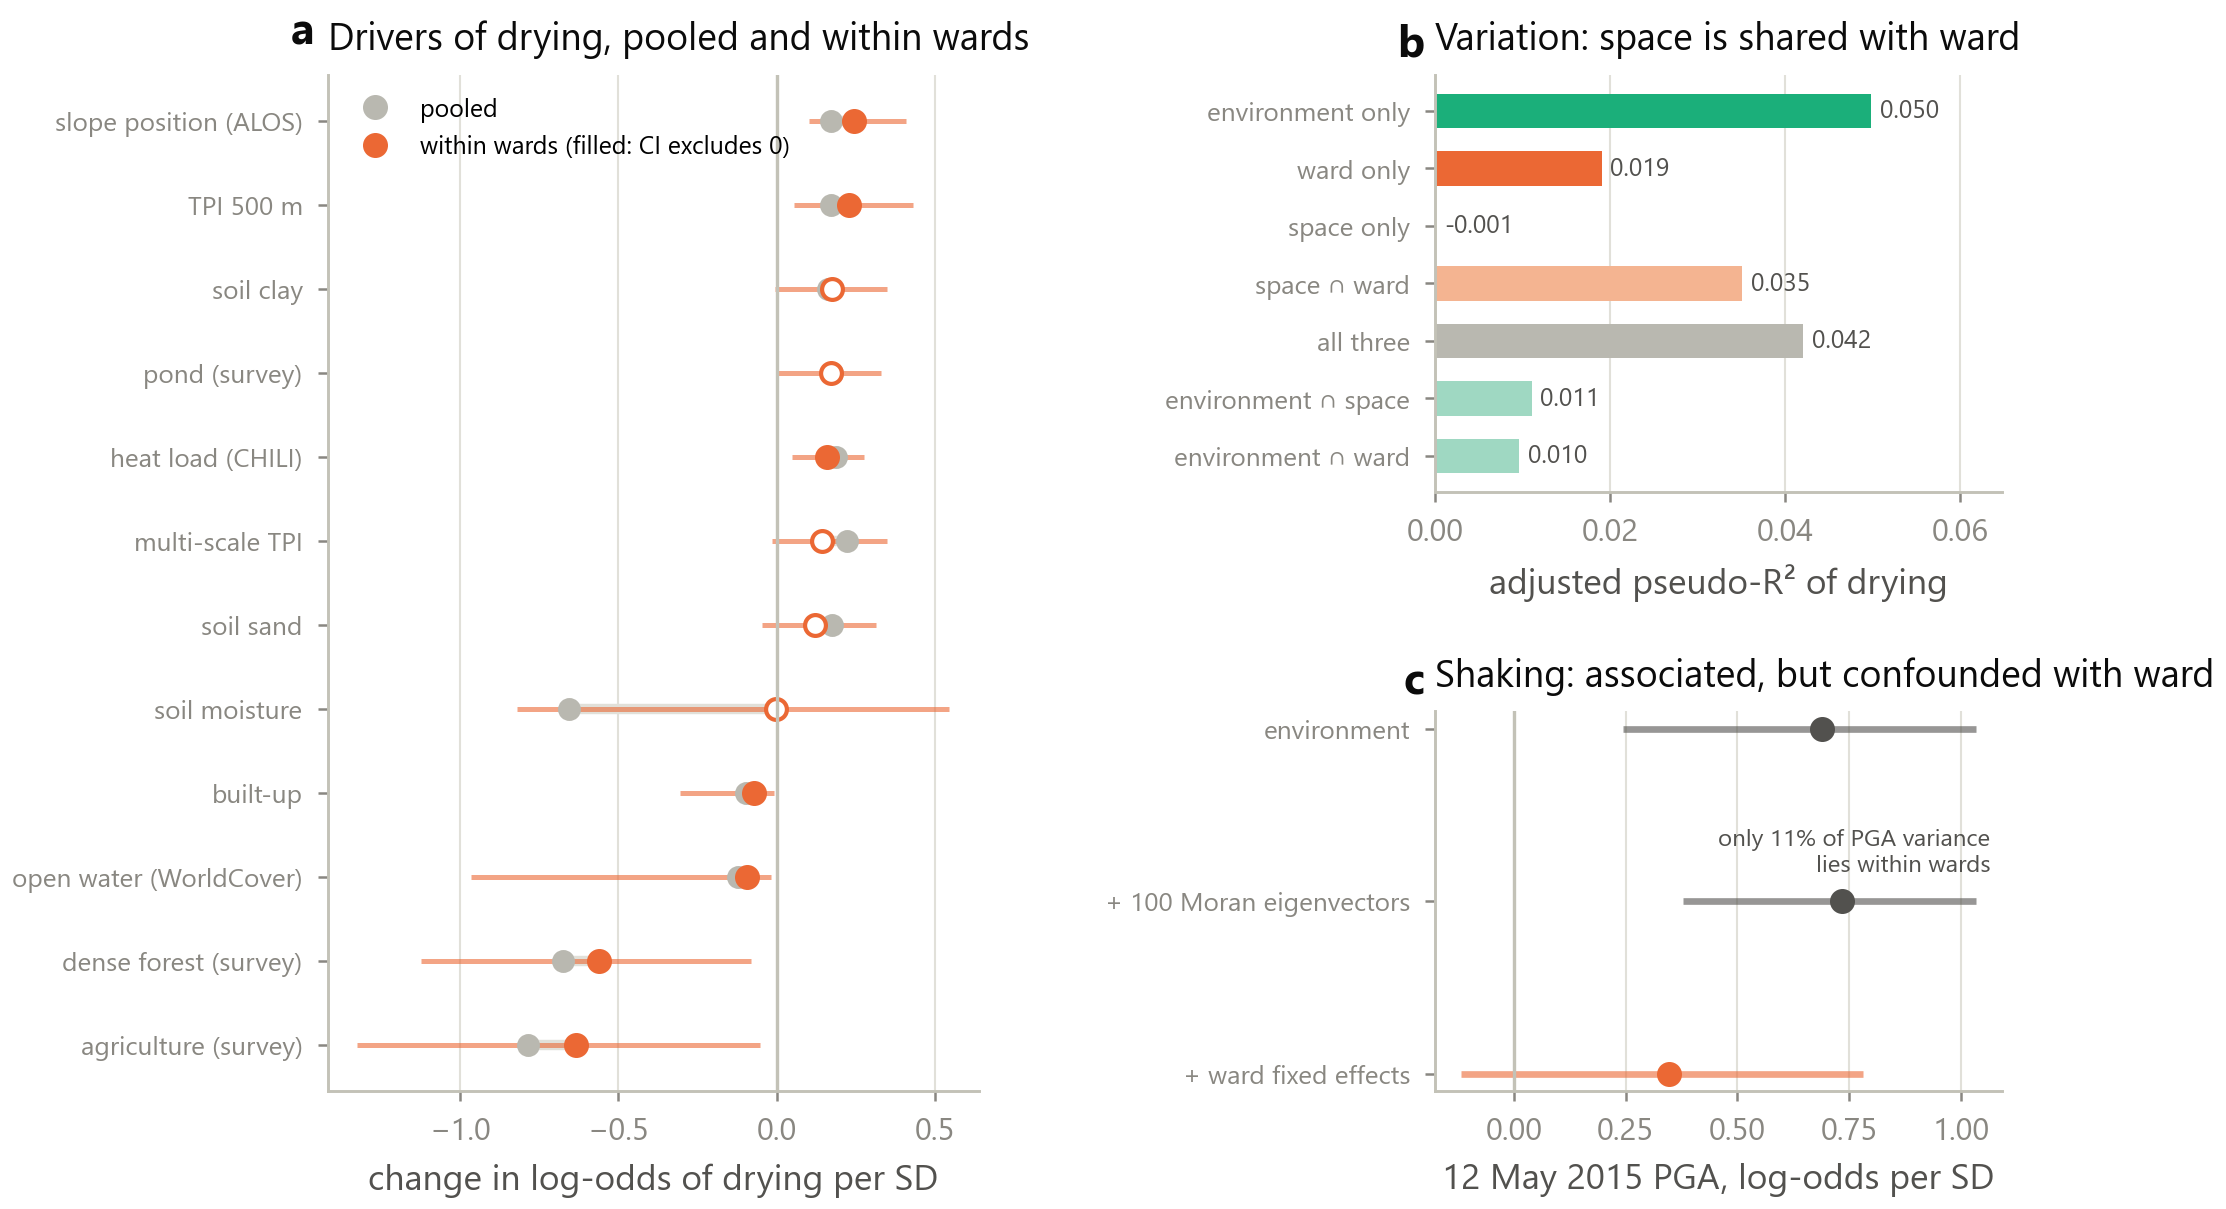

In [5]:
fig("fig7_drivers.png")

In [6]:
d = table("dr_pooled_vs_within_ward.csv")
d.pivot_table(index="term", columns="model", values=["coef_per_sd", "ci_low", "ci_high"]).round(2).head(20)

ci_high                                  ci_low                                  coef_per_sd                                 
model                pooled within ward (ward fixed effects) pooled within ward (ward fixed effects)      pooled within ward (ward fixed effects)
term                                                                                                                                             
Source Type_encoded    0.31                             0.33   0.03                            -0.00        0.18                             0.17
aet                    0.56                             0.38  -0.85                            -1.74       -0.16                            -0.94
aspect_cos             0.21                             0.20  -0.05                            -0.03        0.09                             0.09
aspect_sin             0.04                             0.11  -0.16                            -0.12       -0.07                             0.01
built_2020             0.70                             0.40  -0.14                            -0.47        0.27                            -0.04
built_change           0.17                             0.35  -0.30                            -0.06       -0.08                             0.15
chili                  0.30                             0.28   0.05                             0.05        0.19                             0.16
chirps_anom_2015       1.41                             1.31  -0.48                            -0.36        0.48                             0.18
chirps_trend           0.79                             0.31  -0.92                            -1.50       -0.02                            -0.26
def                    0.53                             0.82  -0.82                            -0.27       -0.07                             0.37
dist_to_road_m         0.19                             0.19  -0.07                            -0.09        0.05                             0.08
elevation_m            1.97                             2.27  -2.44                            -2.23       -0.31                             0.09
elv                    1.69                             1.57  -2.27                            -2.74       -0.21                            -0.64
et_mean                0.08                             0.14  -0.14                            -0.12       -0.04                            -0.00
et_trend               0.11                             0.12  -0.15                            -0.15       -0.02                            -0.02
gfc_loss_post2015      0.03                             0.02  -0.20                            -0.21       -0.06                            -0.07
gfc_loss_pre2015       0.18                             0.17  -0.02                            -0.01        0.09                             0.08
gfc_treecover2000      0.22                             0.20  -0.29                            -0.31       -0.02                            -0.06
hnd                    0.13                             0.18  -0.17                            -0.17       -0.02                             0.03
landform_position      0.31                             0.41   0.06                             0.10        0.17                             0.24

In [7]:
display(table("sa_seismic_quintiles.csv"))
display(table("rb_seismic_within_ward_variance.csv"))
display(table("rb_seismic_adjusted.csv"))
display(table("x7_cause_auc_difference.csv"))
table("x8_ward_correlates.csv")

,q,lo,hi,n,rate,variable
0,0,42.4384,52.2698,1138,0.1424,pga_main
1,1,52.2764,56.0771,1138,0.2627,pga_main
2,2,56.0818,59.5544,1137,0.2823,pga_main
3,3,59.5589,62.5014,1138,0.3181,pga_main
4,4,62.5038,71.2753,1138,0.3313,pga_main
5,0,12.2242,19.7137,1138,0.1344,pga_may12
6,1,19.7165,21.9612,1138,0.2232,pga_may12
7,2,21.9613,23.7754,1137,0.2858,pga_may12
8,3,23.7761,26.0654,1138,0.3163,pga_may12
9,4,26.0671,35.8420,1138,0.3770,pga_may12


,variable,share_of_variance_within_wards,within_ward_sd,total_sd
0,pga_main,0.1104,1.7074,5.1380
1,pga_may12,0.1123,1.4455,4.3137
2,aftershocks_20km,0.0716,1.2609,4.7123


,model,term,coef_per_sd,ci_low,ci_high,ci_excludes_zero
0,seismic + environment,pga_main,-0.2285,-0.7043,0.0707,False
1,seismic + environment,pga_may12,0.6882,0.2435,1.0329,True
2,seismic + environment,aftershocks_20km,-0.2434,-0.5951,0.0388,False
3,seismic + environment + ward fixed effects,pga_main,-0.4389,-1.0482,0.0744,False
4,seismic + environment + ward fixed effects,pga_may12,0.3475,-0.1178,0.7813,False
5,seismic + environment + ward fixed effects,aftershocks_20km,-0.0685,-0.7259,0.3915,False
6,seismic + environment + 100 MEMs (broad and meso spatial structure),pga_main,-0.2677,-0.7000,0.0811,False
7,seismic + environment + 100 MEMs (broad and meso spatial structure),pga_may12,0.7338,0.3790,1.0322,True
8,seismic + environment + 100 MEMs (broad and meso spatial structure),aftershocks_20km,-0.2297,-0.5984,0.0467,False


,model,auc_earthquake,auc_other,diff_other_minus_eq,ci_low,ci_high,p_two_sided,n_earthquake,n_other,n_active
0,Logistic Regression,0.6497,0.7125,0.0628,0.0334,0.0910,0.0005,521,1000,4168
1,CatBoost,0.6783,0.7116,0.0333,0.0061,0.0595,0.0125,521,1000,4168


,ward_covariate,spearman_rho,p,q_bh
0,mapped sources per ward,0.1392,0.2337,0.8634
1,road density (500 m),-0.1273,0.2764,0.8634
2,distance to road,0.1127,0.3358,0.8634
3,built-up growth 2000-20,-0.1351,0.2477,0.8634
4,built-up fraction 2020,-0.0738,0.5292,0.8634
5,population (1 km),-0.0384,0.7434,0.8634
6,night-time lights,-0.0202,0.8634,0.8634
7,elevation,-0.0562,0.6319,0.8634
8,annual precipitation,-0.0249,0.8323,0.8634
9,12 May 2015 PGA,0.0603,0.6076,0.8634


## Collinearity in the joint within-ward model (X15)
The within-ward coefficients come from one model with all 65 covariates and ward indicators. For the
covariates whose interval excludes zero, this compares the joint coefficient with the coefficient when
the covariate enters alone (with ward indicators), and reports its strongest correlate and variance
inflation factor.

In [8]:
table("x15_joint_model_collinearity.csv")

,term,joint_coef_per_sd,joint_ci_low,joint_ci_high,alone_coef_per_sd,alone_ci_low,alone_ci_high,strongest_correlate,max_abs_r,vif_covariates,vif_with_ward_indicators
0,landuse_agriculture,-0.6331,-1.3244,-0.0525,-0.1807,-0.3400,-0.0201,landuse_sparse_forest,0.4551,1058.2218,1076.0301
1,landuse_dense_forest,-0.5595,-1.1227,-0.0797,-0.2187,-0.3476,-0.1265,landuse_sparse_forest,0.3250,696.6275,709.8074
2,tpi_500m,0.2284,0.0547,0.4315,0.5636,0.4459,0.7268,landform_position,0.6673,3.6813,3.9035
3,wc_built,-0.0710,-0.3037,-0.0070,0.2184,0.0522,0.3074,built_2020,0.8320,inf,inf
4,wc_water,-0.0921,-0.9638,-0.0179,-0.0904,-1.5944,-0.0460,wc_bare,0.3701,inf,inf
5,landform_position,0.2446,0.1040,0.4080,0.4934,0.3702,0.6295,mtpi,0.7090,2.9501,3.1315
6,chili,0.1586,0.0486,0.2766,0.1413,0.0482,0.2199,aspect_cos,0.6616,3.3242,3.5667
